# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [2]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [3]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [4]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('north')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [5]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [6]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: suck
step 1 - action: suck
step 2 - action: south
step 3 - action: south
step 4 - action: east
step 5 - action: suck
step 6 - action: west
step 7 - action: east
step 8 - action: west
step 9 - action: suck
step 10 - action: suck
step 11 - action: south
step 12 - action: west
step 13 - action: suck
step 14 - action: west
step 15 - action: west
step 16 - action: east
step 17 - action: south
step 18 - action: east
step 19 - action: suck


7

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

### Thiết kế môi trường

Môi trường lưu trạng thái phòng bằng mảng 2 chiều `dirt` (`True` = bẩn) và vị trí robot `(row, col)`. Ở mỗi bước, môi trường:

1. tạo **percept** gồm 4 bumper (`True` nếu ô kế bên theo hướng đó là tường) và cảm biến `dirty` của ô hiện tại;
2. gọi `agent_function(bumpers, dirty)` để lấy hành động (agent **không** truy cập được mảng `dirt` hay vị trí thật);
3. thực hiện hành động: `suck` làm sạch ô hiện tại, các hướng di chuyển một ô (nếu có tường thì robot đứng yên nhưng vẫn tốn năng lượng);
4. cộng 1 đơn vị năng lượng cho mỗi hành động.

Môi trường dừng khi toàn bộ phòng sạch hoặc khi hết ngân sách `max_steps`. Hàm trả về `(energy, dirty_left)`: tổng năng lượng đã dùng (performance measure) và số ô còn bẩn (bằng 0 nếu dọn xong).

In [7]:
def vacuum_environment(agent_function, n=5, p=0.2, max_steps=100_000, verbose=False):
    """Simulate an n x n room. Returns (energy used, number of squares still dirty)."""
    dirt = np.random.rand(n, n) < p                    # True = dirty square
    row, col = np.random.randint(n), np.random.randint(n)   # random start square
    dirty_left = int(dirt.sum())
    energy = 0

    if verbose:
        print(f"Start at ({row}, {col}); {dirty_left} dirty squares")

    while dirty_left > 0 and energy < max_steps:
        # percepts: 4 bumpers + dirt sensor of the current square
        bumpers = {"north": row == 0, "south": row == n - 1,
                   "west": col == 0, "east": col == n - 1}
        dirty = bool(dirt[row, col])

        action = agent_function(bumpers, dirty)
        energy += 1                                    # every action costs 1 energy unit

        if action == "suck":
            if dirt[row, col]:
                dirt[row, col] = False
                dirty_left -= 1
        elif action == "north" and not bumpers["north"]:
            row -= 1
        elif action == "south" and not bumpers["south"]:
            row += 1
        elif action == "west" and not bumpers["west"]:
            col -= 1
        elif action == "east" and not bumpers["east"]:
            col += 1
        elif action not in actions:
            raise ValueError(f"Invalid action: {action}")
        # otherwise the robot bumped into a wall: it stays, but the energy is spent

        if verbose:
            print(f"step {energy:3d}: dirty={dirty!s:5} action={action:5} -> pos ({row}, {col}), dirty left {dirty_left}")

    return energy, dirty_left

Show that your environment works with the simple randomized agent from above.

In [8]:
np.random.seed(1)
energy, dirty_left = vacuum_environment(simple_randomized_agent, n=5, max_steps=20, verbose=True)
print(f"\nEnergy used: {energy}, squares still dirty: {dirty_left}")

Start at (4, 1); 7 dirty squares
step   1: dirty=False action=north -> pos (3, 1), dirty left 7
step   2: dirty=False action=north -> pos (2, 1), dirty left 7
step   3: dirty=False action=south -> pos (3, 1), dirty left 7
step   4: dirty=False action=west  -> pos (3, 0), dirty left 7
step   5: dirty=False action=east  -> pos (3, 1), dirty left 7
step   6: dirty=False action=north -> pos (2, 1), dirty left 7
step   7: dirty=False action=south -> pos (3, 1), dirty left 7
step   8: dirty=False action=east  -> pos (3, 2), dirty left 7
step   9: dirty=False action=east  -> pos (3, 3), dirty left 7
step  10: dirty=True  action=south -> pos (4, 3), dirty left 7
step  11: dirty=False action=suck  -> pos (4, 3), dirty left 7
step  12: dirty=False action=north -> pos (3, 3), dirty left 7
step  13: dirty=True  action=east  -> pos (3, 4), dirty left 7
step  14: dirty=True  action=south -> pos (4, 4), dirty left 7
step  15: dirty=False action=suck  -> pos (4, 4), dirty left 7
step  16: dirty=False 

Ngân sách 20 bước là quá ít cho một tác tử ngẫu nhiên: nó bỏ qua cảm biến nên thường còn ô bẩn. Môi trường hoạt động đúng: percept được sinh ra, hành động `suck`/di chuyển được áp dụng, tường chặn di chuyển và năng lượng được tính đủ.

## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

**Chiến lược:** luật điều kiện–hành động trên *percept hiện tại*, không có bộ nhớ:

1. nếu `dirty` → `suck`;
2. ngược lại chọn ngẫu nhiên một trong các hướng **không** bị bumper chặn.

Vì không nhớ đã đi đâu nên tác tử đi lại ngẫu nhiên (random walk) và không biết khi nào phòng đã sạch hết.

In [9]:
import random

def simple_reflex_agent(bumpers, dirty):
    if dirty:
        return "suck"
    free = [d for d in ("north", "east", "south", "west") if not bumpers[d]]
    return random.choice(free)      # never walks into a wall

Show how the agent works with your environment.

In [10]:
np.random.seed(1); random.seed(1)
energy, dirty_left = vacuum_environment(simple_reflex_agent, n=5, max_steps=1000)
print(f"Simple reflex agent, 5x5: energy = {energy}, squares still dirty = {dirty_left}")

Simple reflex agent, 5x5: energy = 38, squares still dirty = 0


## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

**Trạng thái của agent (agent state)**

| Biến | Ý nghĩa |
|---|---|
| `phase` | `"north"` → đi lên tường phía bắc; `"west"` → đi sang tường phía tây; `"sweep"` → quét phòng |
| `heading` | hướng quét hiện tại của hàng (`east` hoặc `west`) |
| `row`, `col` | vị trí ước lượng của robot, tính từ góc tây-bắc = `(0, 0)` |

**Cách hoạt động**

1. *Định vị:* robot ban đầu không biết mình ở đâu. Nó đi về phía bắc cho tới khi bumper `north` báo tường, rồi đi về phía tây cho tới khi bumper `west` báo tường. Khi đó nó biết chắc mình ở góc tây-bắc, đặt `(row, col) = (0, 0)`.
2. *Quét có hệ thống (boustrophedon, giống DFS trên lưới):* quét hết một hàng theo `heading`; khi bumper chặn thì xuống một hàng và **đổi chiều** quét. Mỗi ô được thăm đúng một lần.
3. Ở mọi thời điểm, nếu `dirty` thì `suck` trước. Sau khi quét hết hàng cuối cùng thì phòng đã sạch.

Trong lúc đi về góc, robot cũng hút bụi trên đường nên không lãng phí năng lượng. Số hành động kỳ vọng xấp xỉ $n^2$ (quét) + số ô bẩn (`suck`) + quãng đường đến góc.

In [11]:
# The agent state is kept in a dictionary that lives in the closure of the agent function.
# Call make_model_based_reflex_agent() to get a fresh agent (state reset) for each simulation run.

In [12]:
def make_model_based_reflex_agent():
    state = {"phase": "north", "heading": "east", "row": None, "col": None}

    def agent(bumpers, dirty):
        if dirty:                                   # rule 1: always clean the current square
            return "suck"

        if state["phase"] == "north":               # localize: go to the north wall ...
            if not bumpers["north"]:
                return "north"
            state["phase"] = "west"
        if state["phase"] == "west":                # ... then to the west wall (= corner)
            if not bumpers["west"]:
                return "west"
            state.update(phase="sweep", heading="east", row=0, col=0)

        # phase "sweep": walk along the row; at the wall go down one row and turn around
        if not bumpers[state["heading"]]:
            state["col"] += 1 if state["heading"] == "east" else -1
            return state["heading"]
        if not bumpers["south"]:
            state["row"] += 1
            state["heading"] = "west" if state["heading"] == "east" else "east"
            return "south"
        return "suck"                               # last square swept: nothing left to do

    return agent

Show how the agent works with your environment.

In [13]:
np.random.seed(1)
agent = make_model_based_reflex_agent()
energy, dirty_left = vacuum_environment(agent, n=5, max_steps=1000)
print(f"Model-based reflex agent, 5x5: energy = {energy}, squares still dirty = {dirty_left}")

Model-based reflex agent, 5x5: energy = 28, squares still dirty = 0


Agent luôn dọn sạch phòng (`squares still dirty = 0`) với năng lượng gần bằng $n^2$ + số ô bẩn + quãng đường ban đầu. Ta kiểm chứng điều này bằng 100 lần chạy ở Task 4.

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

**Thiết lập thí nghiệm.** Mỗi cấu hình (agent × kích thước) chạy 100 lần với môi trường ngẫu nhiên khác nhau (`np.random.seed` cố định để tái lập). Vì agent ngẫu nhiên và simple reflex có thể không bao giờ dọn xong phòng lớn, mỗi lần chạy có **ngân sách năng lượng** `max_steps`: 100 000 bước cho 5×5 và 10×10, 50 000 bước cho 100×100 (đủ cho model-based, cần khoảng 12 000). Nếu hết ngân sách thì năng lượng ghi nhận là `max_steps` — do đó số liệu của các agent không hoàn thành là **cận dưới** của năng lượng thực sự cần. Bảng có thêm tỉ lệ dọn sạch hoàn toàn và số ô còn bẩn.

Agent ngẫu nhiên dưới đây có cùng chính sách như `simple_randomized_agent` (chọn đều 5 hành động) nhưng dùng `random.choice` thay cho `np.random.choice` vì nhanh hơn nhiều lần khi phải chạy hàng triệu bước.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

def fast_randomized_agent(bumpers, dirty):
    return random.choice(actions)               # same policy as simple_randomized_agent

agents = {
    "Randomized": lambda: fast_randomized_agent,
    "Simple Reflex": lambda: simple_reflex_agent,
    "Model-based Reflex": make_model_based_reflex_agent,   # factory: fresh state per run
}
sizes = {5: 100_000, 10: 100_000, 100: 50_000}             # room size -> energy budget

np.random.seed(42); random.seed(42)
rows = []
for n, budget in sizes.items():
    for name, make_agent in agents.items():
        res = [vacuum_environment(make_agent(), n=n, max_steps=budget) for _ in range(100)]
        energy = np.array([r[0] for r in res]); left = np.array([r[1] for r in res])
        rows.append(dict(size=f"{n}x{n}", agent=name, mean_energy=energy.mean(), std_energy=energy.std(),
                         cleaned_pct=100 * np.mean(left == 0), mean_dirty_left=left.mean()))

results = pd.DataFrame(rows)
table = results.pivot(index="size", columns="agent", values="mean_energy").loc[["5x5", "10x10", "100x100"],
                                                                            list(agents)]
table.round(1)

agent,Randomized,Simple Reflex,Model-based Reflex
size,,,
5x5,442.1,109.8,29.2
10x10,3226.9,984.2,124.7
100x100,50000.0,50000.0,12089.2


Bảng năng lượng trung bình của 100 lần chạy được sinh tự động ở ô code phía trên. Các bảng chi tiết hơn (độ lệch chuẩn, tỉ lệ dọn sạch, số ô còn bẩn):

Tỉ lệ lần chạy dọn sạch hoàn toàn phòng (%):


agent,Randomized,Simple Reflex,Model-based Reflex
size,,,
5x5,100.0,100.0,100.0
10x10,100.0,100.0,100.0
100x100,0.0,0.0,100.0


Số ô bẩn còn lại trung bình khi kết thúc:


agent,Randomized,Simple Reflex,Model-based Reflex
size,,,
5x5,0.0,0.0,0.0
10x10,0.0,0.0,0.0
100x100,1214.7,603.7,0.0


Độ lệch chuẩn của năng lượng:


agent,Randomized,Simple Reflex,Model-based Reflex
size,,,
5x5,233.8,84.3,5.6
10x10,1253.4,483.5,6.9
100x100,0.0,0.0,57.5


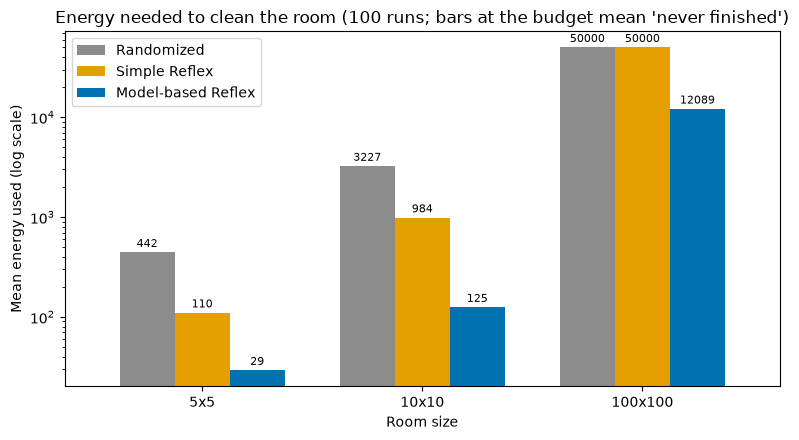

In [15]:
print("Tỉ lệ lần chạy dọn sạch hoàn toàn phòng (%):")
display(results.pivot(index="size", columns="agent", values="cleaned_pct").loc[["5x5", "10x10", "100x100"], list(agents)].round(0))
print("Số ô bẩn còn lại trung bình khi kết thúc:")
display(results.pivot(index="size", columns="agent", values="mean_dirty_left").loc[["5x5", "10x10", "100x100"], list(agents)].round(1))
print("Độ lệch chuẩn của năng lượng:")
display(results.pivot(index="size", columns="agent", values="std_energy").loc[["5x5", "10x10", "100x100"], list(agents)].round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
table.plot.bar(ax=ax, rot=0, color=["#8c8c8c", "#e69f00", "#0072b2"], width=0.75)
ax.set_yscale("log")
ax.set_xlabel("Room size"); ax.set_ylabel("Mean energy used (log scale)")
ax.set_title("Energy needed to clean the room (100 runs; bars at the budget mean 'never finished')")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)
ax.legend(title=None); plt.tight_layout(); plt.show()

### Thảo luận kết quả

* **Model-based reflex agent** luôn dọn sạch 100% phòng và tốn ít năng lượng nhất: trung bình ≈ 29 (5×5), ≈ 125 (10×10) và ≈ 12 100 (100×100). Con số tăng xấp xỉ theo diện tích $n^2$ (cộng số ô bẩn ≈ 0,2 $n^2$ cho hành động `suck`), đúng như phân tích, và độ lệch chuẩn rất nhỏ (≈ 6–7 với phòng nhỏ) vì đường đi cố định, chỉ phụ thuộc vào vị trí xuất phát và ô bẩn cuối cùng.
* **Simple reflex agent** dọn được phòng nhỏ nhưng tốn gấp ≈ 4 lần (109,8 so với 29,2 ở 5×5) và ≈ 8 lần (984 so với 125 ở 10×10). Vì không có bộ nhớ, nó đi lặp lại nhiều ô đã sạch (random walk); thời gian phủ hết phòng tăng nhanh hơn diện tích. Ở 100×100 nó **không** dọn xong trong 50 000 bước ở bất kỳ lần chạy nào và còn ≈ 600 ô bẩn (≈ 30% số ô bẩn ban đầu).
* **Randomized agent** kém nhất: bỏ qua cả cảm biến bụi lẫn bumper (hút ở ô sạch, đâm vào tường). Cần ≈ 442 (5×5) và ≈ 3 227 (10×10) năng lượng, và ở 100×100 còn ≈ 1 200 ô bẩn khi hết ngân sách (0% lần chạy thành công), tức là nó chỉ dọn được khoảng 40% số ô bẩn trong 50 000 bước.
* **Tác động của kích thước phòng:** chi phí của model-based tăng tuyến tính theo diện tích ($\approx$ 12 000 ở 100×100, gấp 100 lần 10×10), còn hai agent không có bộ nhớ tăng nhanh hơn nhiều: 10×10 đã gấp ≈ 9 lần (simple reflex) và ≈ 7 lần (random) so với 5×5 mặc dù diện tích chỉ gấp 4 lần.
* **Kết luận:** trong môi trường không quan sát đầy đủ (agent chỉ thấy ô hiện tại), việc duy trì *trạng thái nội bộ* (đang ở đâu, đã quét đến đâu) cho phép agent suy luận ra phần bản đồ mà nó không quan sát được và tránh lặp lại. Điều này cải thiện hiệu năng lên nhiều bậc, đặc biệt khi phòng lớn. Lưu ý các số liệu của agent không hoàn thành ở 100×100 chỉ là cận dưới.

## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

| Tình huống | Simple reflex | Model-based (quét boustrophedon) |
|---|---|---|
| **Phòng chữ nhật, kích thước chưa biết** | Không đổi: agent không dùng $n$, chỉ dùng bumper. Vẫn dọn được nhưng rất chậm. | **Vẫn đúng.** Agent chỉ dựa vào bumper để rẽ, không dùng $n$ (`row`, `col` chỉ để theo dõi), nên hoạt động với mọi phòng chữ nhật. Chi phí vẫn $\approx$ diện tích. |
| **Hình dạng bất quy tắc** (hành lang nối hai phòng) | Vẫn có thể dọn xong (random walk sẽ đi qua mọi ô liên thông) nhưng thời gian tăng mạnh vì hành lang hẹp là "nút cổ chai". | **Có thể bỏ sót ô.** Bumper `east`/`south` báo tường sớm ở một hàng ngắn khiến agent xuống hàng dưới, và phần phòng nằm lệch/kết nối qua hành lang có thể không bao giờ được thăm. Cần bản đồ nội bộ và tìm kiếm (DFS/BFS) trên các ô chưa thăm. |
| **Có chướng ngại vật** | Vẫn di chuyển được (bumper báo vật cản) và vẫn dọn hết nếu các ô bẩn liên thông; chậm. | **Hỏng.** Vật cản làm bumper báo tường giữa hàng nên agent tưởng đã hết hàng, bỏ qua các ô phía sau; vị trí `(row, col)` cũng sai vì agent tưởng mình chuyển động. Cần agent lập bản đồ (ô đã thăm, ô bị chặn) và luôn đi tới ô chưa thăm gần nhất (DFS). |
| **Cảm biến bụi sai 10%** | Sai lầm làm robot bỏ qua ô bẩn (báo sạch) hoặc hút vô ích (báo bẩn). Vì đi ngẫu nhiên, ô bị bỏ sót có thể được đi qua lại sau đó nên vẫn hiệu quả về lâu dài. | **Mỗi ô chỉ được thăm một lần** nên 10% ô bẩn bị đọc nhầm là sạch sẽ bị bỏ sót vĩnh viễn (không dọn hết). Cải tiến: thăm hai lần (quét lại), hút mỗi ô vài lần / bỏ phiếu đa số nhiều lần đọc trước khi rời ô. |
| **Bumper không báo tường 10%** | Đôi khi đâm vào tường: mất 1 năng lượng và đứng yên, nhưng hành động kế tiếp lại được chọn ngẫu nhiên nên hầu như không ảnh hưởng. | Agent tưởng chưa hết hàng nên đâm vào tường (mất năng lượng) nhưng vẫn tăng `col`/`row` trong bộ nhớ, khiến **vị trí ước lượng sai**. Quét vẫn tiếp diễn ở bước sau khi bumper báo đúng, nên phòng vẫn được dọn nhưng tốn thêm năng lượng; nếu hỏng ở giai đoạn định vị thì agent chỉ tốn thêm vài bước vì nó đợi tới khi bumper báo tường. Cải tiến: chỉ kết luận đến tường sau khi bumper báo nhiều lần liên tiếp. |

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

Phần **Advanced task** (cảm biến bụi sai 10%) và **More Advanced Implementation** không nằm trong yêu cầu của bài thực hành này (đề chỉ yêu cầu ba loại tác tử và so sánh ở 5×5, 10×10, 100×100), nên không được cài đặt. Hướng cải tiến cho model-based agent đã được phác thảo trong Task 5.

## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

*(Không thực hiện — ngoài phạm vi yêu cầu.)*